**Aim:** Implement a Generative Adversarial Network using Python and TensorFlow/Keras to generate synthetic handwritten digit images.

**Dataset:** MNIST handwritten digits

**Components:** Generator, Discriminator, and the combined GAN.


## 1. Learning Objectives

1. Explain the architecture of a GAN.
2. Build Generator and Discriminator networks.
3. Train a GAN using adversarial learning.
4. Generate synthetic images from random noise.
5. Visualize generated images during training.

In [1]:
# If required in Google Colab, uncomment the next line:
# !pip install -q tensorflow matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Reshape, LeakyReLU, Input
from tensorflow.keras.optimizers import Adam

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Load and Preprocess the MNIST Dataset


In [2]:
(X_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

print("Original dataset shape:", X_train.shape)

# Convert pixels from [0, 255] to [-1, 1]
X_train = X_train.astype("float32")
X_train = (X_train - 127.5) / 127.5

# Add channel dimension
X_train = np.expand_dims(X_train, axis=-1)

print("Preprocessed dataset shape:", X_train.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original dataset shape: (60000, 28, 28)
Preprocessed dataset shape: (60000, 28, 28, 1)


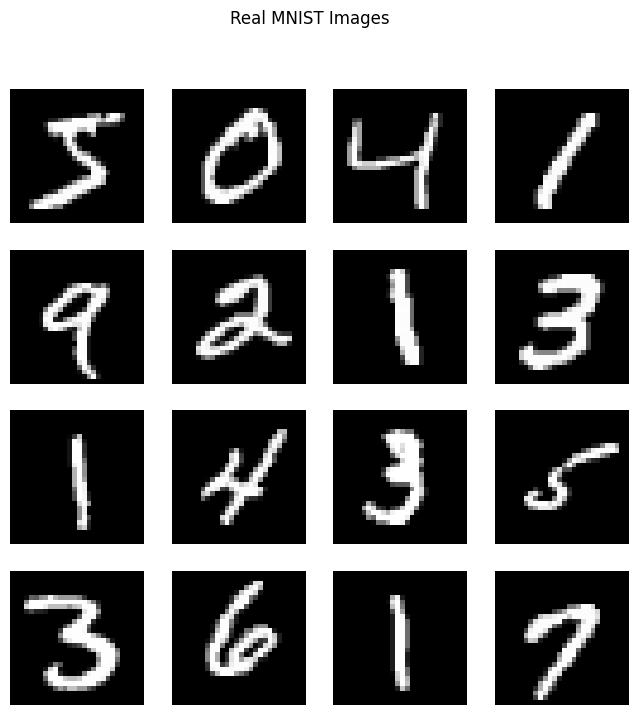

In [3]:
plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Real MNIST Images")
plt.show()


## 3. Define GAN Parameters

- `LATENT_DIM = 100`: size of the random noise vector.
- `BATCH_SIZE = 128`: samples used in one training step.
- `EPOCHS = 30`: number of training epochs.

In [4]:
IMG_SIZE = 28
CHANNELS = 1
LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 30

print("Latent dimension:", LATENT_DIM)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)


Latent dimension: 100
Batch size: 128
Epochs: 30


## 4. Build the Generator

The Generator takes a 100-dimensional random noise vector and produces a 28×28 grayscale image.


In [5]:
def build_generator():
    model = Sequential(name="Generator")
    model.add(Input(shape=(LATENT_DIM,)))
    model.add(Dense(128))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(256))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(28 * 28, activation="tanh"))
    model.add(Reshape((28, 28, 1)))
    return model

generator = build_generator()
generator.summary()


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 784)            │       201,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 247,440 (966.56 KB)

 Trainable params: 247,440 (966.56 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Build the Discriminator

The Discriminator receives a 28×28 image and outputs a probability between 0 and 1.


In [6]:
def build_discriminator():
    model = Sequential(name="Discriminator")
    model.add(Input(shape=(28, 28, 1)))
    model.add(Flatten())
    model.add(Dense(256))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(128))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Dense(1, activation="sigmoid"))
    return model

discriminator = build_discriminator()

discriminator.compile(
    optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

discriminator.summary()


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 233,985 (914.00 KB)

 Trainable params: 233,985 (914.00 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Build the Complete GAN

The Discriminator is frozen while the Generator is trained through the combined GAN.


In [7]:
discriminator.trainable = False

gan = Sequential(name="GAN")
gan.add(generator)
gan.add(discriminator)

gan.compile(
    optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)

gan.summary()


Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       247,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       233,985 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 481,425 (1.84 MB)

 Trainable params: 247,440 (966.56 KB)

 Non-trainable params: 233,985 (914.00 KB)

## 7. Function to Display Generated Images


In [8]:
def generate_images(epoch, rows=4, cols=4):
    noise = np.random.normal(0, 1, (rows * cols, LATENT_DIM))
    generated = generator.predict(noise, verbose=0)
    generated = (generated + 1) / 2.0

    plt.figure(figsize=(8, 8))
    for i in range(rows * cols):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(generated[i].reshape(28, 28), cmap="gray")
        plt.axis("off")

    plt.suptitle(f"Generated Images — Epoch {epoch}")
    plt.tight_layout()
    plt.show()


## 8. Train the GAN

Each epoch has two stages:

1. Train the Discriminator using real and generated images.
2. Train the Generator so that generated images are classified as real.


In [9]:
def train_gan(epochs, batch_size):
    half_batch = batch_size // 2

    for epoch in range(1, epochs + 1):

        # Train Discriminator on real images
        idx = np.random.randint(0, X_train.shape[0], half_batch)
        real_images = X_train[idx]
        real_labels = np.ones((half_batch, 1))

        # Generate fake images
        noise = np.random.normal(0, 1, (half_batch, LATENT_DIM))
        fake_images = generator.predict(noise, verbose=0)
        fake_labels = np.zeros((half_batch, 1))

        d_loss_real = discriminator.train_on_batch(real_images, real_labels)
        d_loss_fake = discriminator.train_on_batch(fake_images, fake_labels)

        d_loss = 0.5 * (
            np.array(d_loss_real) + np.array(d_loss_fake)
        )

        # Train Generator through GAN
        noise = np.random.normal(0, 1, (batch_size, LATENT_DIM))
        valid_labels = np.ones((batch_size, 1))

        g_loss = gan.train_on_batch(noise, valid_labels)

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"D Loss: {d_loss[0]:.4f} | "
                f"D Accuracy: {100*d_loss[1]:.2f}% | "
                f"G Loss: {float(g_loss):.4f}"
            )
            generate_images(epoch)


## 9. Start Training


/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch 01/30 | D Loss: 0.6250 | D Accuracy: 66.02% | G Loss: 0.6767


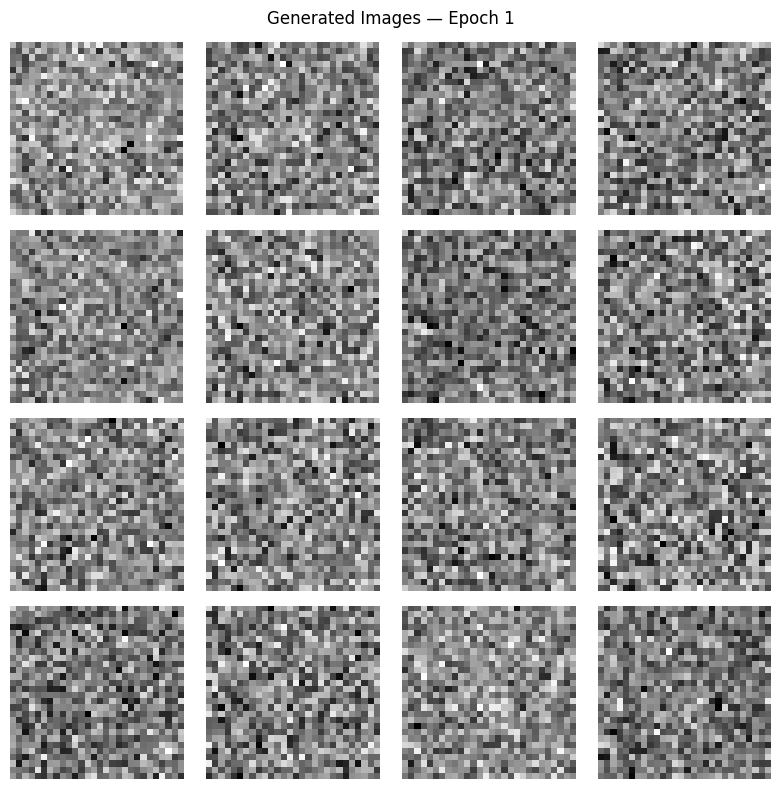

Epoch 05/30 | D Loss: 0.7476 | D Accuracy: 40.90% | G Loss: 0.5184


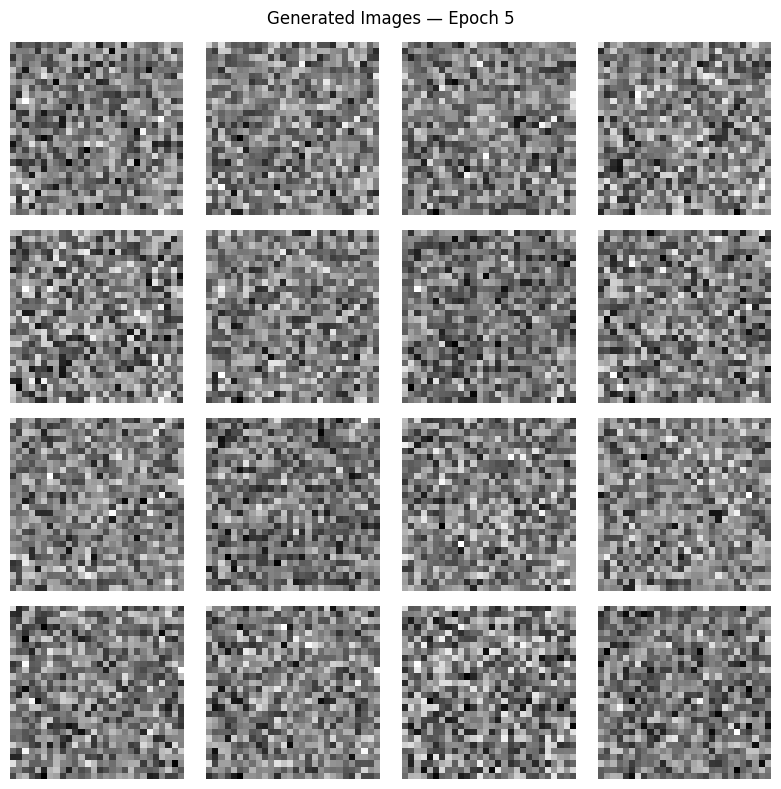

Epoch 10/30 | D Loss: 0.9080 | D Accuracy: 36.72% | G Loss: 0.3812


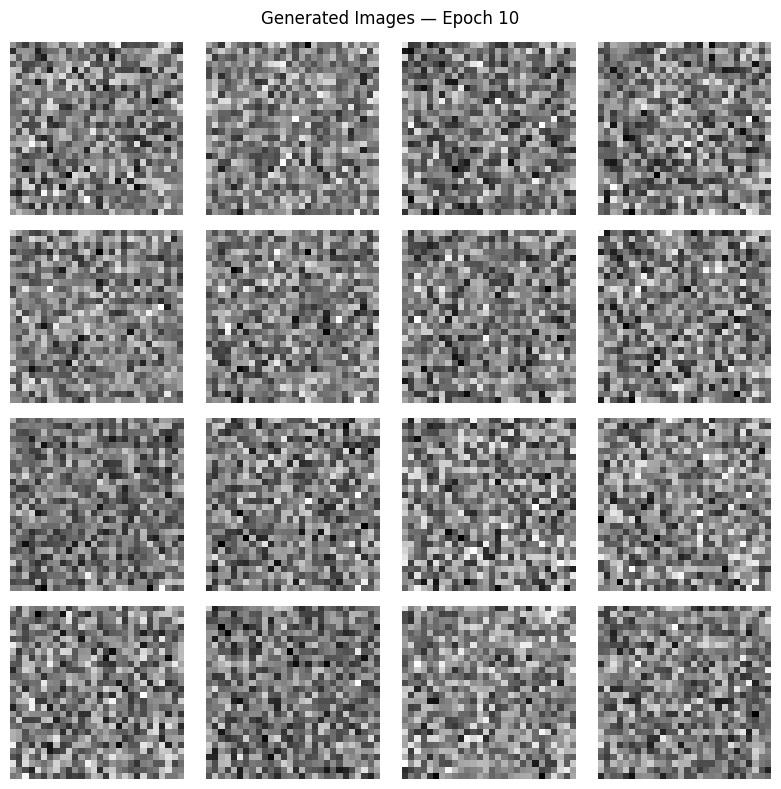

Epoch 15/30 | D Loss: 1.0811 | D Accuracy: 34.97% | G Loss: 0.2922


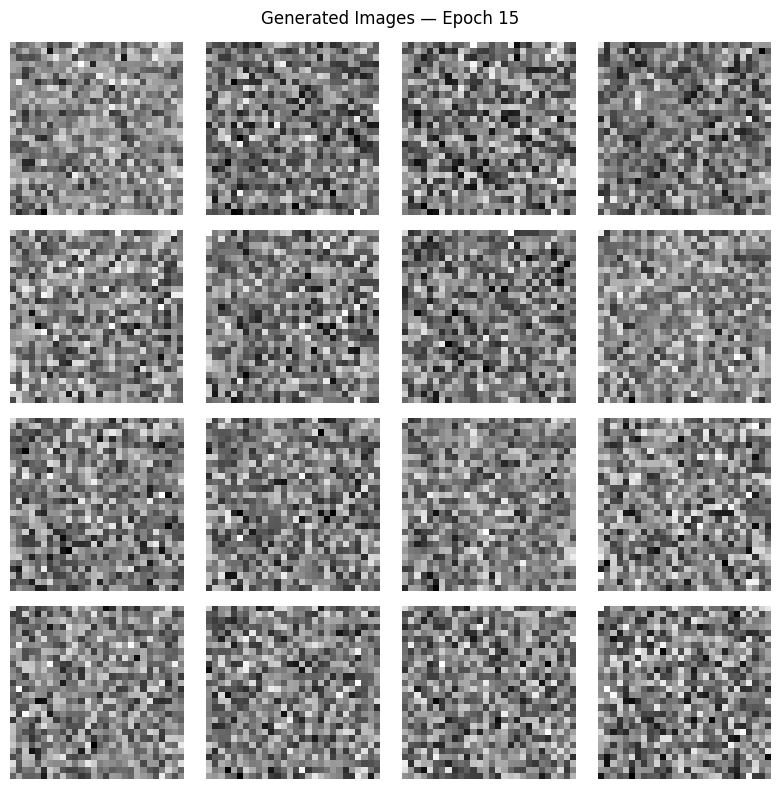

Epoch 20/30 | D Loss: 1.2384 | D Accuracy: 34.46% | G Loss: 0.2346


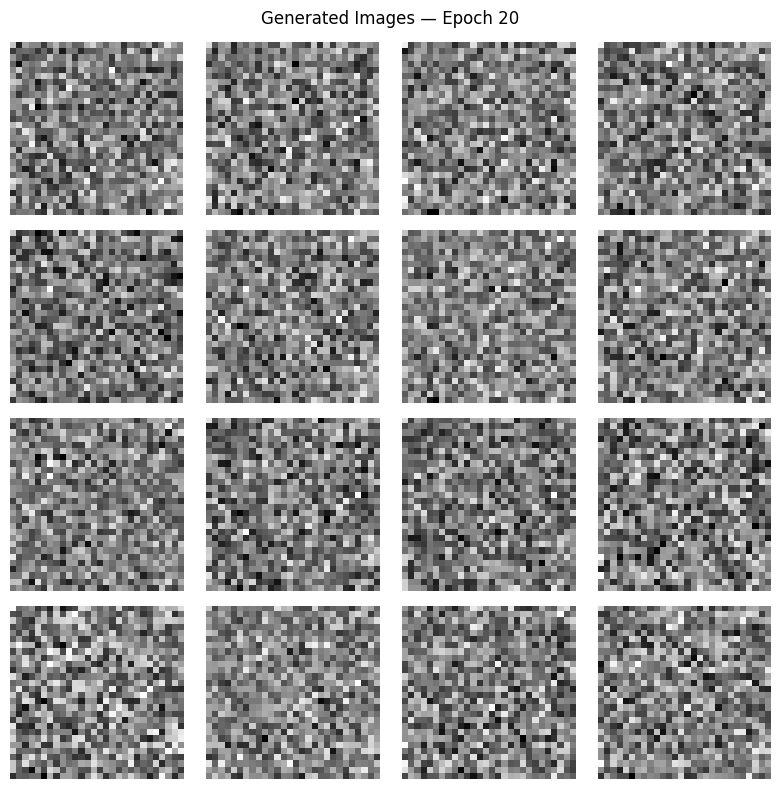

Epoch 25/30 | D Loss: 1.3891 | D Accuracy: 34.09% | G Loss: 0.1956


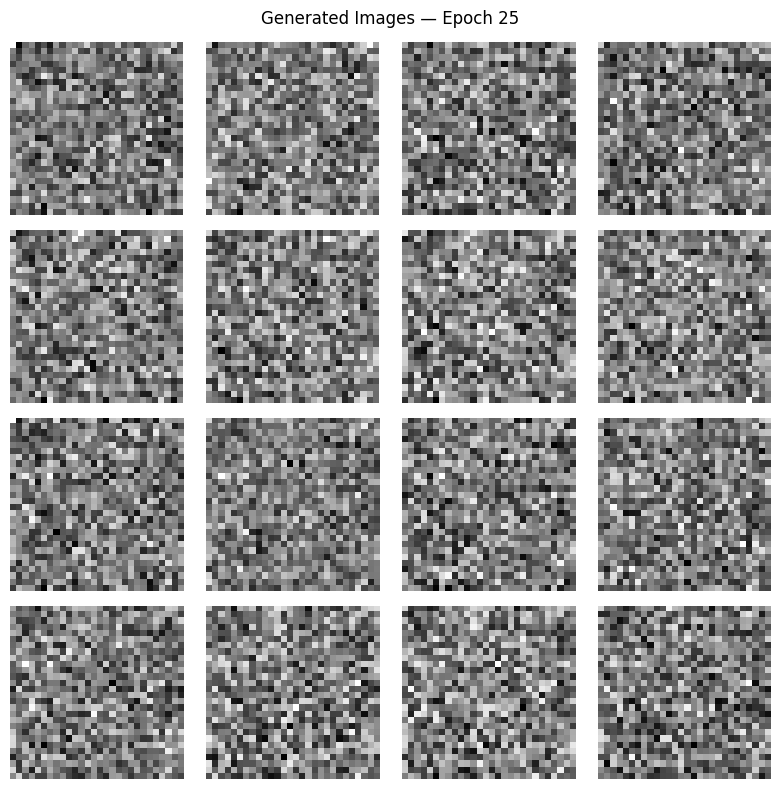

Epoch 30/30 | D Loss: 1.5214 | D Accuracy: 34.09% | G Loss: 0.1674


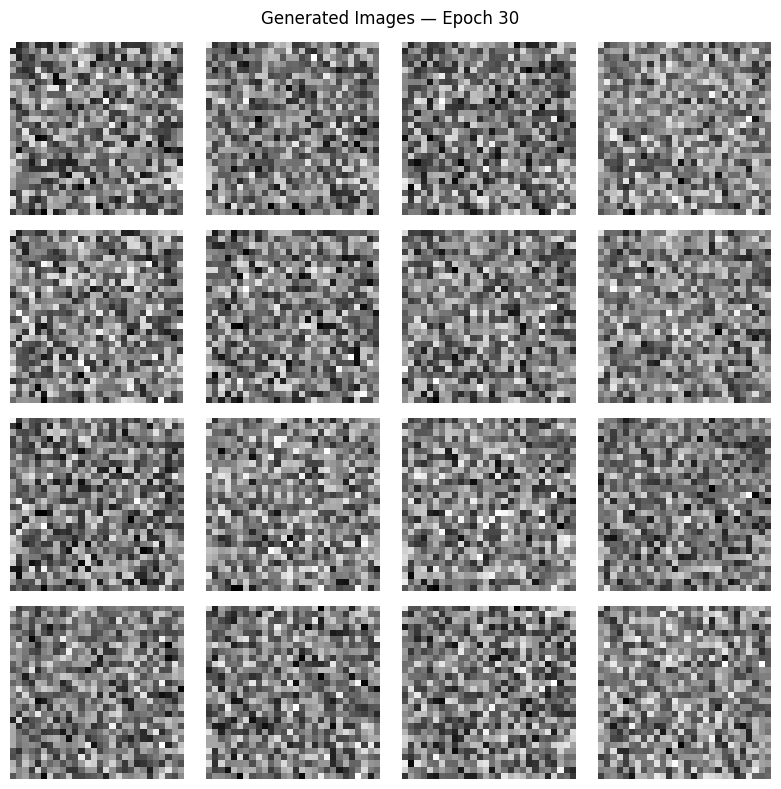

In [10]:
train_gan(EPOCHS, BATCH_SIZE)


## 10. Generate Final Synthetic Images


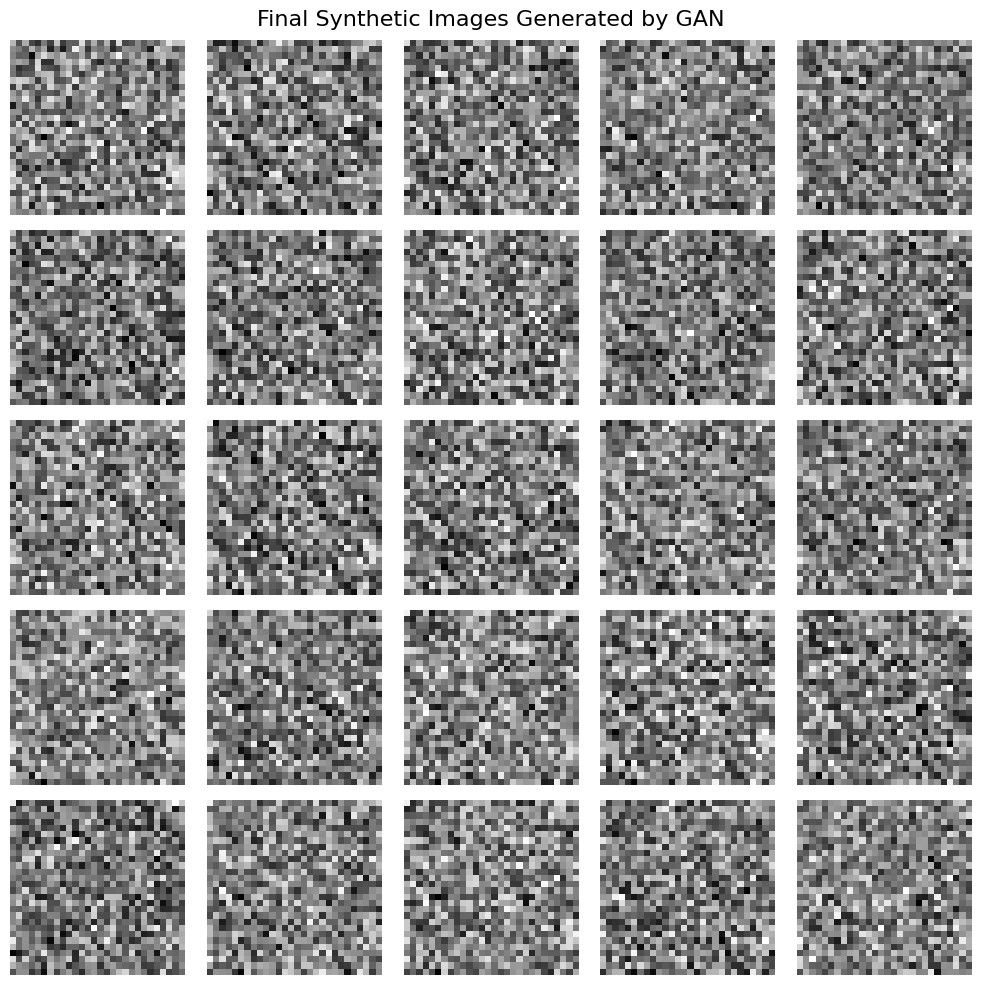

In [11]:
noise = np.random.normal(0, 1, (25, LATENT_DIM))

final_images = generator.predict(noise, verbose=0)
final_images = (final_images + 1) / 2.0

plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(final_images[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Final Synthetic Images Generated by GAN", fontsize=16)
plt.tight_layout()
plt.show()


## 11. Save the Generator Model


In [12]:
generator.save("mnist_gan_generator.keras")
print("Generator saved as mnist_gan_generator.keras")


Generator saved as mnist_gan_generator.keras


## 12. Generate One New Synthetic Digit


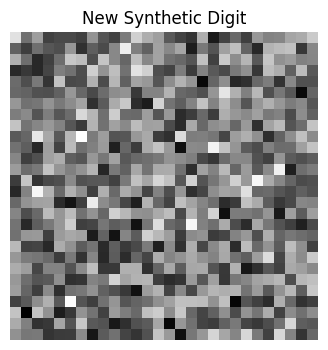

In [13]:
noise = np.random.normal(0, 1, (1, LATENT_DIM))

new_image = generator.predict(noise, verbose=0)
new_image = (new_image + 1) / 2.0

plt.figure(figsize=(4, 4))
plt.imshow(new_image[0].reshape(28, 28), cmap="gray")
plt.title("New Synthetic Digit")
plt.axis("off")
plt.show()


## 13. Viva Questions

1. What is a Generative Adversarial Network?
2. What are the two main components of GAN?
3. What is the role of the Generator?
4. What is the role of the Discriminator?
5. What is a latent vector?
6. Why is `tanh` used in the Generator output?
7. Why is `sigmoid` used in the Discriminator output?
8. Why is Binary Cross-Entropy used?
9. What happens if the Discriminator becomes too strong?
10. Mention four real-world applications of GANs.

## Result

The GAN was successfully implemented using TensorFlow/Keras, and synthetic handwritten digit images were generated from random noise.
